# LAB 10 — Fine-tuning và Document QA


In [6]:
import sys,json,inspect
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display
LAB_DIR=Path.cwd()/'lab10' if (Path.cwd()/'lab10/qa_model.py').is_file() else Path.cwd()
sys.path.insert(0,str(LAB_DIR.resolve()))
import qa_model as qa
qa.configure()
tokenizer=qa.BertTokenizerFast.from_pretrained(qa.assets(),do_lower_case=True)
data=qa.prepare_data()
print({k:len(v) for k,v in data.items()})

{'train': 3000, 'validation': 300, 'test': 600}


#### 14. Experiment 1 — Context Length

Giữ cùng splits, tokenizer, khởi tạo pretrained, seed, LR, batch size, epochs, stride và decoding; thay max_length 128/256/384. Mỗi cấu hình khởi tạo lại, không học tiếp từ run trước. Thay độ dài làm thay số window và optimizer steps, nên không phải so sánh bằng compute budget. Thời gian tính bằng giây, gồm train + validation/decoding + sao chép best state; không gồm download, tokenization, test hay pretraining.


In [7]:
if not (qa.CACHE/'evidence.json').exists():
    qa.run()
evidence=json.loads((qa.CACHE/'evidence.json').read_text(encoding='utf-8'))
if set(evidence['runs'])!={'128','256','384'}:
    raise RuntimeError('Chạy qa_model.py để hoàn tất ba cấu hình trước khi phân tích.')
length_results=pd.DataFrame([r['row'] for r in evidence['runs'].values()])
display(length_results[['Max length','EM','F1','Training time']])
display(length_results[['Max length','Train windows','Test windows','Answer-covered test questions']])

,Max length,EM,F1,Training time
0,128,9.833333,21.335430,119.809100
1,256,16.333333,27.567479,121.302796
2,384,14.666667,27.292827,157.693859


,Max length,Train windows,Test windows,Answer-covered test questions
0,128,7217,1533,600
1,256,3302,665,600
2,384,3032,607,600


**Tăng context length có luôn cải thiện QA không?** Không có bảo đảm. F1 ở 128/256/384 lần lượt là 21.3354, 27.5675, 27.2928. Độ dài thay đổi lượng context mỗi window, số window cạnh tranh và số bước train. Coverage cho biết gold có nằm trọn trong ít nhất một window, chưa đo mức hiểu context. Chọn cấu hình triển khai phải dựa vào validation và ngân sách, không chọn lại theo test.


#### 15. Core Implementation

Question + Context → tokenizer → input_ids/attention_mask/offset_mapping/overflow_to_sample_mapping → pretrained encoder → contextual representations → start/end logits → constrained decoding → answer. Phần triển khai nằm trong `qa_model.py`, được gọi trực tiếp và in dưới đây; không dùng `pipeline("question-answering")`.

- `input_ids`: chỉ số token của cặp question/context.
- `attention_mask`: vị trí thật và PAD.
- `offset_mapping`: vị trí ký tự để ánh xạ nhãn và khôi phục nguyên văn answer.
- `overflow_to_sample_mapping`: window thuộc sample nào trong batch; nhiều window có thể cùng một sample.

Các vị trí question, special tokens và PAD không được chọn làm đáp án. Decoder xét top-20 start/end, ràng buộc end≥start và tối đa 64 WordPiece; đây là giới hạn tìm kiếm có thể bỏ lỡ answer dài.


In [8]:
print(inspect.getsource(qa.PretrainedSpanQA))
print(inspect.getsource(qa.encode_rows))
row=data['test'][0]
features=qa.encode_rows(tokenizer,[row],qa.BASE_LENGTH)
print('Windows:',len(features))
display(pd.DataFrame({'window':range(len(features)),'overflow_to_sample_mapping':[f['sample'] for f in features],
                     'start_position':[f['start_position'] for f in features],'end_position':[f['end_position'] for f in features]}))
feature=features[0]
display(pd.DataFrame({'tokens':tokenizer.convert_ids_to_tokens(feature['input_ids']),
 'input_ids':feature['input_ids'],'attention_mask':feature['attention_mask'],
 'sequence_ids':feature['sequence_ids'],'offset_mapping':feature['offset_mapping']}))

class PretrainedSpanQA(nn.Module):
    """Input IDs -> encoder -> token representations -> start/end logits."""
    def __init__(self,pretrained=True):
        super().__init__();path=CACHE/'bert-tiny'
        config=BertConfig.from_pretrained(path);config._attn_implementation='eager'
        self.encoder=BertModel.from_pretrained(path,config=config,add_pooling_layer=False) if pretrained else BertModel(config,add_pooling_layer=False)
        self.dropout=nn.Dropout(.1);self.span_classifier=nn.Linear(config.hidden_size,2)
    def forward(self,input_ids,attention_mask,token_type_ids):
        contextual_representations=self.encoder(input_ids=input_ids,attention_mask=attention_mask,token_type_ids=token_type_ids).last_hidden_state
        span_logits=self.span_classifier(self.dropout(contextual_representations))
        start_logits,end_logits=span_logits.unbind(-1)
        return start_logits,end_logits

def encode_rows(tokenizer,rows,max_length=BASE_LENGTH,stride=STRIDE):
    questions=[

,window,overflow_to_sample_mapping,start_position,end_position
0,0,0,117,124


,tokens,input_ids,attention_mask,sequence_ids,offset_mapping
0,[CLS],101,1,NaN,"[0, 0]"
1,what,2054,1,0.0,"[0, 4]"
2,did,2106,1,0.0,"[5, 8]"
3,john,2198,1,0.0,"[9, 13]"
4,dunn,14145,1,0.0,"[14, 18]"
...,...,...,...,...,...
138,in,1999,1,1.0,"[614, 616]"
139,the,1996,1,1.0,"[617, 620]"
140,city,2103,1,1.0,"[621, 625]"
141,.,1012,1,1.0,"[625, 626]"


#### 16. Answer Span Alignment

Tìm token chứa ký tự đầu và token chứa ký tự cuối của answer. Nếu answer nằm giữa token, nhãn bao phủ toàn token nên chuỗi decode có thể rộng hơn annotation; không thể cắt một phần token bằng token index. Nếu gold bị cắt hoặc ngoài window, dùng CLS=(0,0), không chọn một span giả trong phần còn lại.


In [9]:
print(inspect.getsource(qa.token_span))
offsets=[(0,0),(0,5),(6,10),(0,0)]
sequence_ids=[None,1,1,None]
cases=[('Bắt đầu giữa token',2,5),('Kết thúc giữa token',0,3),
       ('Bị truncation ở cuối',6,15),('Ngoài window',20,25)]
display(pd.DataFrame([{'Case':name,'Character span':(a,b),'Token span':qa.token_span(offsets,sequence_ids,a,b)} for name,a,b in cases]))
assert qa.token_span(offsets,sequence_ids,2,5)==(1,1)
assert qa.token_span(offsets,sequence_ids,0,3)==(1,1)
assert qa.token_span(offsets,sequence_ids,6,15)==(0,0)
assert qa.token_span(offsets,sequence_ids,20,25)==(0,0)

toy={'id':'visible-pipeline','question':'What is the capital of France?',
     'context':'The capital of France is Paris.',
     'answers':[{'text':'Paris','answer_start':25}]}
toy_features=qa.encode_rows(tokenizer,[toy])
model=qa.load_model()
batch=qa.collate(toy_features)
with torch.no_grad():
    start_logits,end_logits=model(**{k:batch[k] for k in ['input_ids','attention_mask','token_type_ids']})
display(pd.DataFrame({'tokens':tokenizer.convert_ids_to_tokens(toy_features[0]['input_ids']),
                     'start_logits':start_logits[0].numpy(),'end_logits':end_logits[0].numpy()}))
print('Start/end shapes:',tuple(start_logits.shape),tuple(end_logits.shape))
toy_prediction,_=qa.infer(model,toy_features,[toy])
print('Decoded prediction:',toy_prediction[0])


def token_span(offsets,sequence_ids,answer_start,answer_end):
    context=[i for i,s in enumerate(sequence_ids) if s==1 and offsets[i][1]>offsets[i][0]]
    if not context or offsets[context[0]][0]>answer_start or offsets[context[-1]][1]<answer_end:return 0,0
    starts=[i for i in context if offsets[i][0]<=answer_start<offsets[i][1]]
    ends=[i for i in context if offsets[i][0]<answer_end<=offsets[i][1]]
    return (starts[0],ends[-1]) if starts and ends else (0,0)

Start/end shapes: (1, 17) (1, 17)
Decoded prediction: {'id': 'visible-pipeline', 'answer': 'Paris', 'start_char': 25, 'end_char': 30, 'start_token': 14, 'end_token': 14, 'score': 7.772171497344971, 'window': 0}


,Case,Character span,Token span
0,Bắt đầu giữa token,"(2, 5)","(1, 1)"
1,Kết thúc giữa token,"(0, 3)","(1, 1)"
2,Bị truncation ở cuối,"(6, 15)","(0, 0)"
3,Ngoài window,"(20, 25)","(0, 0)"


,tokens,start_logits,end_logits
0,[CLS],2.420340,1.020922
1,what,-3.228194,-4.243745
2,is,-3.510899,-4.472820
3,the,-1.918811,-5.438103
4,capital,-3.036763,-3.747134
5,of,-4.047139,-5.127597
6,france,-3.247160,-2.975086
7,?,-4.394827,-2.846518
8,[SEP],-3.209735,-3.679431
9,the,3.161456,-2.018582


#### 17. Experiment 2 — Pretrained QA Model

Fine-tune encoder BERT-Tiny và head start/end mới. Dùng T=256 làm cấu hình cơ sở cố định; chọn epoch bằng validation F1 cao nhất, không mặc định epoch cuối. Phần test có 600 câu hỏi, có nhiều gold references khi dataset cung cấp.


Cả ba cấu hình chọn epoch 2. Training loss tiếp tục giảm ở epoch 3 trong khi validation loss tăng và validation F1 giảm, phù hợp với dấu hiệu overfitting trong lịch train hiện tại. Kết quả test dùng checkpoint epoch 2 đã chọn từ validation.


,Epoch,Training loss,Validation loss,Validation EM,Validation F1
0,1,4.016743,3.501110,13.666667,24.584909
1,2,3.192155,3.390128,16.666667,27.927762
2,3,2.423742,3.497699,14.666667,27.114710


,Model,EM,F1
0,Fine-tuned Transformer,16.333333,27.567479


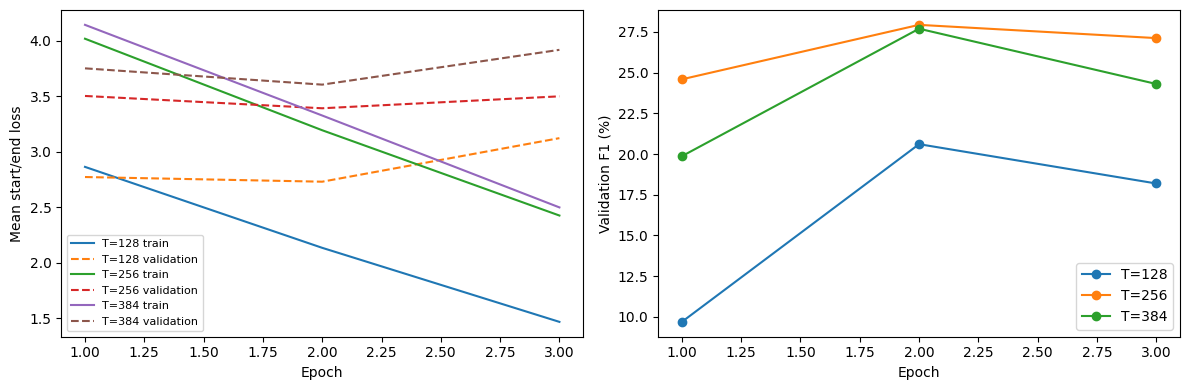

In [10]:
base=evidence['runs'][str(qa.BASE_LENGTH)]
display(pd.DataFrame(base['history']))
display(pd.DataFrame([base['row']])[['Model','EM','F1']])
fig,axes=plt.subplots(1,2,figsize=(12,4))
for length,run in evidence['runs'].items():
    history=pd.DataFrame(run['history'])
    axes[0].plot(history.Epoch,history['Training loss'],label=f'T={length} train')
    axes[0].plot(history.Epoch,history['Validation loss'],'--',label=f'T={length} validation')
    axes[1].plot(history.Epoch,history['Validation F1'],marker='o',label=f'T={length}')
axes[0].set(xlabel='Epoch',ylabel='Mean start/end loss');axes[0].legend(fontsize=8)
axes[1].set(xlabel='Epoch',ylabel='Validation F1 (%)');axes[1].legend()
plt.tight_layout();fig.savefig(LAB_DIR/'learning_curves.png',dpi=150);plt.show()

#### 18. Exact Match

EM bằng 1 khi answer sau normalization giống một gold answer. Normalization SQuAD gồm lowercase, bỏ dấu câu ASCII, articles a/an/the và chuẩn hóa khoảng trắng. EM không đo mức đúng ngữ nghĩa ngoài những gold references đã cho. Metric báo cáo theo %, không phải tỉ lệ 0–1.


In [11]:
display(pd.DataFrame([{'Gold':gold,'Prediction':pred,'EM':qa.answer_scores(pred,gold)[0]}
 for gold,pred in [('Paris','Paris'),('Paris','the city of Paris'),('Paris','the Paris')]]))

,Gold,Prediction,EM
0,Paris,Paris,1.0
1,Paris,the city of Paris,0.0
2,Paris,the Paris,1.0


#### 19. Token-level F1 for QA

Gold `Paris France`, prediction `France`: overlap=1, P=1/1=1, R=1/2=0.5, F1=2/3≈0.6667. Token ở đây là whitespace word sau normalization, không phải WordPiece. Dùng Counter để đếm overlap có số lần xuất hiện, không dùng set làm mất từ lặp. Với nhiều references, lấy EM/F1 lớn nhất theo từng metric.


In [12]:
print('EM/F1:',qa.answer_scores('France','Paris France'))
print('Repeated token example:',qa.answer_scores('Paris','Paris Paris'))

EM/F1: (0.0, 0.6666666666666666)
Repeated token example: (0.0, 0.6666666666666666)


#### 20. Experiment 3 — EM vs F1

Baseline và Transformer T=256 dùng đúng cùng 600 test questions. Các ví dụ partial có EM=0 và F1>0 cho thấy overlap từ không đồng nghĩa đúng toàn answer.


,Model,EM,F1
0,Baseline,7.666667,16.805296
1,Fine-tuned Transformer,16.333333,27.567479


,Question,Gold,Prediction,EM,F1,Explanation
0,What would the local council of Newcastle like...,national networks | national networks | to nat...,"National Cycling strategy, Newcastle first dev...",0.0,0.153846,Có từ sau normalization trùng gold nhưng thừa/...
1,What was the name of the leader through the Gr...,James Bryant Conant | James Bryant Conant | Ja...,1900. James Bryant Conant,0.0,0.857143,Có từ sau normalization trùng gold nhưng thừa/...
2,When did Martin Luther publish his translation...,1522 | 1522 | 1522,"1522, and he and his collaborators completed t...",0.0,0.142857,Có từ sau normalization trùng gold nhưng thừa/...
3,All Italian chocolate is made from what alone?,cocoa butter | cocoa butter | cocoa butter,butter,0.0,0.666667,Có từ sau normalization trùng gold nhưng thừa/...
4,When did Kenya become an independent country?,1963 | Kenya Independence Act | 1963,Kenya,0.0,0.500000,Có từ sau normalization trùng gold nhưng thừa/...


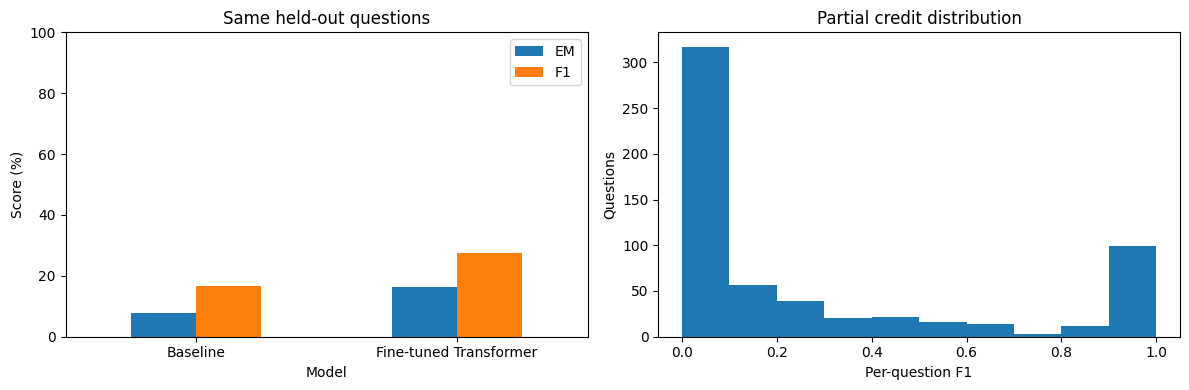

In [13]:
comparison=pd.DataFrame([evidence['baseline']['row'],base['row']])
display(comparison[['Model','EM','F1']])
analysis=json.loads((qa.CACHE/'analysis.json').read_text(encoding='utf-8'))
display(pd.DataFrame(analysis['partial']))
fig,axes=plt.subplots(1,2,figsize=(12,4))
comparison.set_index('Model')[['EM','F1']].plot.bar(ax=axes[0],rot=0)
axes[0].set(ylabel='Score (%)',ylim=(0,100),title='Same held-out questions')
point_scores=[max(qa.answer_scores(p['answer'],a['text'])[1] for a in r['answers']) for r,p in zip(data['test'],base['predictions'])]
axes[1].hist(point_scores,bins=np.linspace(0,1,11));axes[1].set(xlabel='Per-question F1',ylabel='Questions',title='Partial credit distribution')
plt.tight_layout();fig.savefig(LAB_DIR/'em_f1_analysis.png',dpi=150);plt.show()

#### 21. Baseline

Question → keyword overlap → candidate sentence → candidate span. Chọn câu theo số từ trùng question có điều chỉnh độ dài; heuristic ưu tiên số cho when/how many, tên viết hoa cho who, rồi phrase sau is/was hoặc tên riêng. Không fit hoặc dùng gold khi dự đoán, không điều chỉnh heuristic theo test.


In [14]:
print(inspect.getsource(qa.lexical_baseline))
display(pd.DataFrame([{'Question':r['question'],'Gold':r['answers'][0]['text'],'Prediction':p['answer']}
 for r,p in zip(data['test'][:5],evidence['baseline']['predictions'][:5])]))

def lexical_baseline(row):
    """Chọn câu nhiều keyword overlap nhất, trả phrase sau is/was hoặc tên/số."""
    context=row['context'];question=row['question'];q=set(normalize(question).split())
    candidates=list(re.finditer(r'[^.!?]+(?:[.!?]|$)',context))
    if not candidates:return {'id':row['id'],'answer':'','start_char':0,'end_char':0}
    sent=max(candidates,key=lambda m:len(q&set(normalize(m.group()).split()))/(1+len(set(normalize(m.group()).split()))**.5))
    text=sent.group();patterns=[]
    if re.search(r'\b(when|year|how many|how much)\b',question.lower()):patterns.append(r'\b\d[\d,]*(?:\.\d+)?\b')
    if re.match(r'\s*who\b',question.lower()):patterns.append(r'\b[A-Z][a-z]+(?:\s+[A-Z][a-z]+){0,3}')
    patterns.extend([r'\b(?:is|was|were|are)\s+([^,;.]+)',r'\b[A-Z][a-z]+(?:\s+[A-Z][a-z]+){0,3}'])
    for pattern in patterns:
        m=re.search(pattern,text)
        if m:
            a,b=m.span(1) if m.lastindex else m.span();a+=sent.start();b+=sent.start()
            

,Question,Gold,Prediction
0,What did John Dunn invent?,keyed Northumbrian smallpipes,John Dunn
1,When was Warsaw ranked as the 32nd most liveab...,2012,2012
2,What would the local council of Newcastle like...,national networks,partially or completely isolated
3,What properties are analyzed with a conoscopic...,"birefringence, pleochroism, twinning, and inte...",analyzed through a petrographic microscope
4,What was the name of the leader through the Gr...,James Bryant Conant,James Bryant Conant


#### 22. Experiment 4 — Question/Context Matching

Định nghĩa overlap=|question content words∩context words|/|question content words|, bỏ danh sách stop words cố định. Chia high≥0.75 và lower<0.75. Đây là proxy từ vựng, không tự chứng minh nhóm low là paraphrase ngữ nghĩa.


In [15]:
display(pd.DataFrame(analysis['matching']))
display(pd.DataFrame(analysis['matching_examples']))
display(pd.DataFrame(analysis['matching_pair_metrics']))
display(pd.DataFrame(analysis['matching_pairs']))
display(pd.DataFrame(analysis['controls']))

,Group,Samples,EM,F1
0,High overlap (≥0.75),250,19.6,30.367055
1,Lower overlap (<0.75),350,14.0,25.567782


,Group,Question,Gold,Prediction,Overlap
0,High overlap (≥0.75),When was Warsaw ranked as the 32nd most liveab...,2012,Warsaw,1.000000
1,High overlap (≥0.75),What properties are analyzed with a conoscopic...,"birefringence, pleochroism, twinning, and inte...",a conoscopic lens. In the electron microprobe,1.000000
2,High overlap (≥0.75),What was the name of the leader through the Gr...,James Bryant Conant,1900. James Bryant Conant,0.750000
3,Lower overlap (<0.75),What did John Dunn invent?,keyed Northumbrian smallpipes,the city,0.666667
4,Lower overlap (<0.75),What would the local council of Newcastle like...,national networks,"National Cycling strategy, Newcastle first dev...",0.555556
5,Lower overlap (<0.75),When did Martin Luther publish his translation...,1522,"1522, and he and his collaborators completed t...",0.714286


,Question type,Samples,EM,F1
0,Lexical match,6,50.000000,66.666667
1,Paraphrase,6,66.666667,72.222222


,Pair,Question type,Question,Context,Gold,Prediction
0,0,Lexical match,What city is the capital of France?,The capital of France is Paris.,Paris,Paris
1,1,Lexical match,What did Marie Curie discover?,Marie Curie discovered radium in 1898.,radium,1898
2,2,Lexical match,When will the conference begin?,The conference will begin on Monday.,Monday,The conference will begin on Monday
3,3,Lexical match,When does the library close?,The library closes at six in the evening.,six in the evening,six in the evening
4,4,Lexical match,Within how many days must students return books?,Students must return books within fourteen days.,fourteen days,fourteen
5,5,Lexical match,Who did the committee select as its chair?,The committee selected Alice as its chair.,Alice,Alice
6,0,Paraphrase,Where is the French national government based?,The capital of France is Paris.,Paris,Paris
7,1,Paraphrase,Which element was identified by the scientist ...,Marie Curie discovered radium in 1898.,radium,1898
8,2,Paraphrase,On which day is the meeting scheduled to start?,The conference will begin on Monday.,Monday,The conference will begin on Monday
9,3,Paraphrase,What time does the book-lending facility shut ...,The library closes at six in the evening.,six in the evening,six in the evening


,Condition,Samples,EM,F1
0,Original,50,12.0,22.993072
1,Question-word distractor,50,12.0,21.514819
2,Reversed sentences,50,16.0,25.484259


**Lexical match và paraphrase:** Sáu cặp tự biên soạn giữ nguyên context và gold, thay cách diễn đạt question. Bảng đối chiếu trực tiếp output của từng cặp, không gán mọi câu có overlap thấp thành paraphrase. Tập này nhỏ và theo mẫu, chưa đại diện mọi cách diễn đạt.

**Đối chiếu Prediction 1, 3, 4:** Thử nghiệm distractor/order dùng cùng model T=256 và cùng tập con 50 câu: giữ context gốc; thêm một câu chỉ lặp lại question mà không cung cấp answer; đảo thứ tự câu trong khi giữ nguyên mọi gold answer text. Bảng hiển thị cả cải thiện và suy giảm thực tế, không giả định distractor luôn làm giảm. Đảo câu có thể đổi quan hệ tham chiếu hoặc ý nghĩa, nên đây là kiểm tra độ nhạy với phép biến đổi, chưa tách riêng một nguyên nhân. Các gold offsets ở context biến đổi được cập nhật trước khi đánh giá.


#### 23. Experiment 5 — Answer Length

Nhóm theo số word thô trong gold reference đầu tiên (quy tắc cố định); EM/F1 vẫn chấm theo tất cả references. Không dùng WordPiece để chia nhóm.


,Answer length,EM,F1
0,1,22.167488,29.294078
1,2–3,16.535433,26.483586
2,4–6,11.000000,29.740637
3,7+,0.000000,20.764999


,Answer length,Samples
0,1,203
1,2–3,254
2,4–6,100
3,7+,43


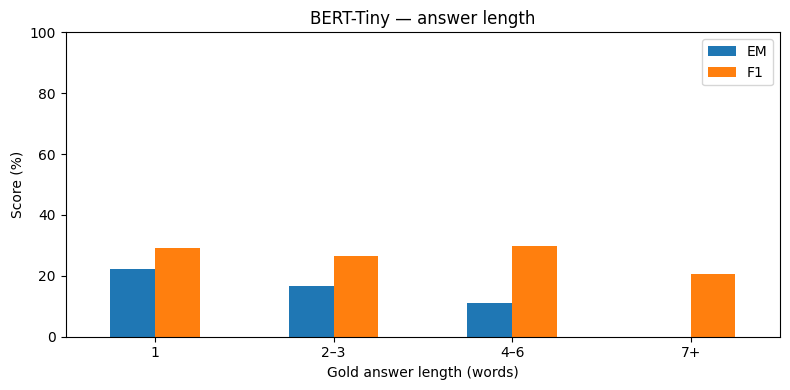

In [16]:
answer_length=pd.DataFrame(analysis['length'])
display(answer_length[['Answer length','EM','F1']]);display(answer_length[['Answer length','Samples']])
fig,ax=plt.subplots(figsize=(8,4))
answer_length.set_index('Answer length')[['EM','F1']].plot.bar(ax=ax,rot=0)
ax.set(xlabel='Gold answer length (words)',ylabel='Score (%)',ylim=(0,100),title='BERT-Tiny — answer length')
plt.tight_layout();fig.savefig(LAB_DIR/'answer_length_analysis.png',dpi=150);plt.show()

**Đối chiếu Prediction 2:** EM theo nhóm 1/2–3/4–6/7+ là 22.1675, 16.5354, 11.0000, 0.0000; F1 là 29.2941, 26.4836, 29.7406, 20.7650. Chênh lệch còn phụ thuộc loại câu hỏi, số mẫu và context; không suy ra quan hệ nhân quả chỉ từ độ dài.


#### 24. Error Analysis

Chọn 5 wrong start nhưng end đúng, 5 wrong end nhưng start đúng và 5 sai cả hai boundary, chỉ trong các câu có EM=0. Gold và prediction được ghi bằng text; explanation đối chiếu character spans với context, không mặc định mọi sai sót do câu khó.


In [17]:
display(pd.DataFrame(analysis['errors'])[['Question','Gold','Prediction','Error type','Explanation']])

,Question,Gold,Prediction,Error type,Explanation
0,What was the name of the leader through the Gr...,James Bryant Conant,1900. James Bryant Conant,wrong start,"Gold chars [899,918), pred [893,918); có phần ..."
1,All Italian chocolate is made from what alone?,cocoa butter,butter,wrong start,"Gold chars [2007,2019), pred [2013,2019); có p..."
2,What was Temüjin' sister's name?,Temülen,"Hachiun, and Temüge, and one sister named Temülen",wrong start,"Gold chars [82,89), pred [40,89); có phần giao..."
3,Which logo had the DW Tardis insignia removed?,The logo for the Twelfth Doctor,Twelfth Doctor,wrong start,"Gold chars [933,964), pred [950,964); có phần ..."
4,Who holds an annual International Arts Fair in...,NewcastleGateshead,"late August bank holiday weekend, is an annual...",wrong start,"Gold chars [188,206), pred [28,206); có phần g..."
5,When did Martin Luther publish his translation...,1522,"1522, and he and his collaborators completed t...",wrong end,"Gold chars [68,72), pred [68,157); có phần gia..."
6,What are BSkyB's standard definition broadcast...,DVB-compliant MPEG-2,"DVB-compliant MPEG-2, with the Sky Movies and ...",wrong end,"Gold chars [46,66), pred [46,115); có phần gia..."
7,What do the Treaties generally limit?,free trade,"free trade, to prioritise other values such as...",wrong end,"Gold chars [1975,1985), pred [1975,2120); có p..."
8,The hardest problems in NP can be analogously ...,NP-complete,NP-complete problems contains the most difficu...,wrong end,"Gold chars [244,255), pred [244,491); có phần ..."
9,The use of what device represented the last ma...,steam turbines,steam turbines starting in the late part of th...,wrong end,"Gold chars [68,82), pred [68,218); có phần gia..."


#### 25. Wrong Start vs Wrong End

Boundary được đối chiếu với mọi character span gold. #wrong_start và #wrong_end có thể chồng nhau, không cộng hai số thành số câu sai. Đây là độ khớp vị trí annotation: một answer giống text ở vị trí khác vẫn có thể được EM chấp nhận nhưng lệch offsets.


In [18]:
display(pd.DataFrame([analysis['boundary_counts']]))

,# wrong start,# wrong end,# both boundaries wrong
0,445,449,386


**Giả thuyết:** End sai có thể liên quan thêm/bớt modifier hoặc punctuation; start sai có thể bỏ mất từ đầu như tên đầy đủ. Hai đầu đều sai có thể là chọn vùng thông tin khác. Cần đọc các cặp span và chạy phép can thiệp để xác định nguyên nhân; số đếm không tự chứng minh tokenization hay truncation gây lỗi.


#### 26. No-Answer Extension

Core dùng SQuAD 1.1 và không huấn luyện/đánh giá SQuAD 2.0. Context được cung cấp không bảo đảm chứa đáp án. CLS labels cho window thiếu gold chỉ phục vụ học theo window, chưa đủ để tuyên bố model biết abstain ở cấp câu hỏi. Hệ thống hiện luôn chọn một context span; với câu không trả lời được, span có thể sai dù score cao. Mở rộng cần tập no-answer, null score và ngưỡng chọn trên validation; không tự đặt ngưỡng từ test.


#### 27. Application — Document QA

User question → context/document được nhập trực tiếp → QA model → answer span. Dùng đoạn FAQ thư viện tự biên soạn. Các câu trả lời dưới đây là output thực tế, không phải gold đã sửa lại cho đúng; FAQ chưa được dùng train.


In [19]:
from document_qa import answer_question
print(analysis['document_context'])
display(pd.DataFrame(analysis['document_examples']))

The university library opens at 8 a.m. on weekdays. Students can borrow up to five books. Books must be returned within fourteen days. The help desk is on the second floor.


,Question,Answer,Start character,End character (exclusive),Windows,Span score
0,How many books can students borrow?,five,78,82,1,8.858181
1,Where is the help desk?,8 a.m. on weekdays. Students can borrow up to ...,32,133,1,7.466256
2,When must books be returned?,five,78,82,1,9.220968


#### 28. Phân biệt QA và RAG

**Extractive QA:** Question + Context → QA model → Answer span có sẵn trong context.

**RAG:**

```text
Question
    ↓
Retriever
    ↓
Relevant documents
    ↓
Context
    ↓
Generator / QA model
    ↓
Answer
```

LAB 10 giả định context đã có, không triển khai truy hồi. LAB 11 mới chuyển sang Question → Retrieval → Relevant documents, chuẩn bị cho RAG ở LAB 12. Generator có thể sinh câu trả lời, còn extractive QA chỉ lấy span; retrieval sai hoặc context thiếu thông tin vẫn ảnh hưởng bước trả lời.


#### 30. Reproducibility

| Trường | Giá trị |
| --- | --- |
| Model | prajjwal1/bert-tiny; 2 layers, hidden 128, 2 heads; revision 6f75de8b60a9f8a2fdf7b69cbd86d9e64bcb3837 |
| Tokenizer | BertTokenizerFast, uncased WordPiece; question trước context; question tối đa 48 subword |
| Dataset | SQuAD 1.1; answerable questions; lưu SHA256 các JSON gốc |
| Train split | 3.000 câu hỏi lấy ngẫu nhiên không lặp từ official train; seed 42 |
| Validation split | 300 câu từ nhóm context riêng trong official dev; dùng chọn epoch cao nhất validation F1 |
| Test split | 600 câu từ nhóm context còn lại trong official dev, không trùng context validation/train; không phải hidden official test |
| Max sequence length | 128/256/384; application cố định 256; gồm question và special tokens |
| Stride | 64 subword overlap ở mọi cấu hình |
| Batch size | 16; dynamic padding theo batch |
| Learning rate | 0.0003 |
| Epochs | 3; khởi tạo lại mỗi cấu hình |
| Optimizer | AdamW; weight_decay=0.01; gradient clipping norm=1.0 |
| Random seed | 42 |
| Hardware | CPU AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD; torch 4 threads; không GPU |
| Training time | Train + validation decoding + copy best state; giây; không preprocessing/download/test/pretraining |


In [20]:
import platform,hashlib,importlib.metadata as metadata
display(length_results[['Max length','Best epoch','Training time']])
print('Python',platform.python_version(),'torch',torch.__version__)
for package in ['transformers','tokenizers','huggingface-hub','safetensors','numpy','pandas']:print(package,metadata.version(package))
for split in ['train','dev']:
    path=qa.CACHE/f'{split}-v1.1.json';print(path.name,hashlib.sha256(path.read_bytes()).hexdigest())
for split,rows in data.items():print(split,'ID SHA256',qa.fingerprint([r['id'] for r in rows]))

Python 3.12.7 torch 2.11.0+cpu
transformers 5.22.2
tokenizers 0.23.3
huggingface-hub 2.4.0
safetensors 0.8.0
numpy 1.26.4
pandas 2.2.2
train-v1.1.json 3527663986b8295af4f7fcdff1ba1ff3f72d07d61a20f487cb238a6ef92fd955
dev-v1.1.json 95aa6a52d5d6a735563366753ca50492a658031da74f301ac5238b03966972c9
train ID SHA256 a73044c98848ff6635be2c3e2c34fb1bf8af543e3fa3e0b391c1335509e3fdc0
validation ID SHA256 52d280d98950953616e4185948035e7ee17570c94f6649e7bd9224ebfae5f243
test ID SHA256 2e55a8f5601f1edd7b261e531ea729b6d54a6a2210a7a853c51661b027acc1a0


,Max length,Best epoch,Training time
0,128,2,119.809100
1,256,2,121.302796
2,384,2,157.693859


#### 31. Deliverables

Bộ nộp gồm README, calculations, prediction, hai notebook, qa_model.py, document_qa.py, results.csv, ba ảnh phân tích, error_analysis và reflection. Cache dữ liệu, checkpoint, predictions và metadata nằm ngoài thư mục nộp trong `.lab10_cache/`. CSV có ba cấu hình Transformer và một dòng baseline; EM/F1 theo thang 0–100.


#### 34. Reflection

```text
Pretrained Transformer
          ↓
Contextual representations
          │
   ┌──────┼─────────┐
   ↓      ↓         ↓
 [CLS] Token reps Token reps
   ↓      ↓         ↓
 Class   NER     Start / End
   ↓      ↓         ↓
 LAB 08 LAB 09    LAB 10
```


LAB 08, LAB 09 và LAB 10 dùng pretrained Transformer nhưng khác đơn vị dự đoán. Backbone nhận token IDs và tạo vector theo ngữ cảnh ở từng vị trí. Các vector này là đầu vào cho prediction head; kiến trúc head và nhãn đích quyết định mô hình phải học tác vụ nào. Tái sử dụng encoder không có nghĩa ba bài toán có cùng output hoặc cùng cách đánh giá.

Ở LAB 08, sentiment classification lấy representation tại [CLS] rồi đưa qua Linear để dự đoán một nhãn cho cả review. Loss so sánh logits lớp với positive hoặc negative. Trong LAB 09, head được áp dụng chung lên các token representations để tạo logits BIO. Mỗi vị trí được giám sát có một nhãn, còn entity chỉ đúng khi cả loại và ranh giới khớp gold. Vì tokenizer có thể tách một word thành nhiều mảnh, alignment và ignore index trở thành phần quan trọng của pipeline.

LAB 10 nhận thêm question cùng context. Head Linear với hai đầu ra tại mỗi token tạo start logits và end logits. Hai cross-entropy được lấy trung bình; decoder tìm một cặp hợp lệ rồi dùng offset mapping lấy lại text trong context. Start và end token dùng chỉ số inclusive, trong khi slicing ký tự dùng end exclusive. Nhãn đích là hai vị trí, khác một sequence label hoặc một dãy nhãn BIO. Thay đổi prediction head vì thế kéo theo thay đổi chuẩn bị dữ liệu và post-processing.

Trong thí nghiệm QA, baseline đạt F1 16.8053, Transformer T=256 đạt 27.5675 trên cùng 600 câu hỏi holdout. Đây là số đo của BERT-Tiny fine-tuned với 3.000 câu train, không đại diện mọi pretrained model. EM yêu cầu toàn answer khớp sau normalization; F1 cho điểm overlap nên có thể ghi nhận một phần đáp án dù boundary sai. Các bảng lỗi giúp phân biệt sai đầu, sai cuối và chọn nhầm vùng thông tin.

Một backbone dùng được cho nhiều tác vụ vì contextual representation giữ thông tin phục vụ nhiều cách đọc khác nhau. Tuy nhiên, head khởi tạo mới vẫn cần dữ liệu và fine-tuning phù hợp. Context dài, window thiếu gold, distractor và câu hỏi không có đáp án vẫn là giới hạn. QA hiện tại nhận context trực tiếp và chỉ chọn span; retrieval ở LAB 11 mới tìm tài liệu, còn RAG thêm chuỗi xử lý dựa trên tài liệu được tìm. Chất lượng representation hữu ích phải được kiểm tra bằng target và metric của từng tác vụ.
